# Figure 5 supplementary analyses

## Option 2-FS versus Option 3 at ico4

All four models use the same 196 CN participants, 4,687 masked ico4 vertices, subject order, nested 5 × 5 folds, training-fold median imputation and standardization, LSQR Ridge, and 21 alphas spanning $10^{-4}$ to $10^6$.

Option 2-FS MD uses `mri_vol2surf` in verified pial-to-white order (depth 0: `projfrac=1.0`; depth 20: `projfrac=0.0`). Its length feature is native corresponding-vertex pial–white Euclidean distance mapped through `sphere.reg` with `mri_surf2surf`; it is not FreeSurfer thickness. Feature validation and 4,704 source-value checks passed before training.

Panel A shows OOF MAE with subject-bootstrap 95% intervals. Panel B shows only the two matched O2-FS minus Option 3 contrasts (MD profile and MD profile + length), with 95% percentile intervals from 10,000 bootstrap samples. These intervals are conditional on fixed fitted folds; bootstrap replicates do not refit models.


,model,n,mae,rmse,pearson_r,r2
0,o2fs_ico4_md,196,5.392,7.009,0.756,0.554
1,ico4_md,196,5.291,6.939,0.761,0.563
2,o2fs_ico4_md_length,196,5.317,6.909,0.765,0.567
3,ico4_md_length,196,5.233,6.851,0.770,0.574


,model_a,model_b,delta_mae_a_minus_b,ci95_lower,ci95_upper,bootstrap_replicates,seed
0,o2fs_ico4_md,ico4_md,+0.102,-0.106,+0.314,10000,20261102
1,o2fs_ico4_md_length,ico4_md_length,+0.083,-0.114,+0.287,10000,20261102


Figure and source tables: /mnt/newStor/paros/paros_WORK/xintong/result/cortical_trajectory_analysis/analysis_results/figure5/outputs/figures/supplement


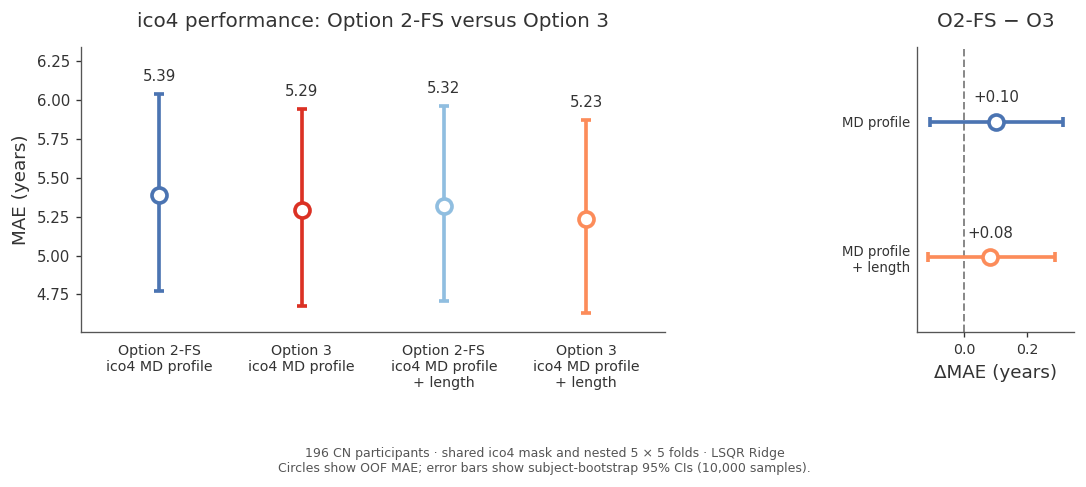

In [1]:
%matplotlib inline
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# All plotting code is kept here so this figure can be adjusted directly in the notebook.
REPO_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
                 if (p / 'qc/publication_style.py').is_file())
sys.path.insert(0, str(REPO_ROOT))
from qc.publication_style import PALETTE, set_publication_style

COMPARISON = Path('/mnt/newStor/paros/paros_WORK/xintong/results/figure5_age_prediction/outputs/option2_fs_baselines/comparison')
OUTPUT = REPO_ROOT / 'analysis_results/figure5/outputs/figures/supplement'
OUTPUT.mkdir(parents=True, exist_ok=True)

MODELS = [
    'o2fs_ico4_md',
    'ico4_md',
    'o2fs_ico4_md_length',
    'ico4_md_length',
]
MODEL_LABELS = [
    'Option 2-FS\nico4 MD profile',
    'Option 3\nico4 MD profile',
    'Option 2-FS\nico4 MD profile\n+ length',
    'Option 3\nico4 MD profile\n+ length',
]
MODEL_COLORS = [PALETTE['blue'], PALETTE['red'], PALETTE['light_blue'], PALETTE['orange']]
PAIRS = [
    ('o2fs_ico4_md', 'ico4_md'),
    ('o2fs_ico4_md_length', 'ico4_md_length'),
]
PAIR_LABELS = ['MD profile', 'MD profile\n+ length']
PAIR_COLORS = [PALETTE['blue'], PALETTE['orange']]

# Load model summaries and retain only the two matched O2-FS - Option 3 contrasts.
metrics = pd.read_csv(COMPARISON / 'model_metrics.csv').set_index('model').loc[MODELS]
paired_all = pd.read_csv(COMPARISON / 'paired_bootstrap_differences.csv')
paired = paired_all.set_index(['model_a', 'model_b']).loc[PAIRS].reset_index()

# Recompute model-level subject-bootstrap CIs from aligned OOF predictions.
BOOTSTRAP_SEED = 20261102
N_BOOTSTRAP = 10_000
N_SUBJECTS = 196
rng = np.random.default_rng(BOOTSTRAP_SEED)
bootstrap_indices = rng.integers(0, N_SUBJECTS, (N_BOOTSTRAP, N_SUBJECTS))
ci_rows = []
reference_alignment = None

for model in MODELS:
    predictions = pd.read_csv(COMPARISON / f'{model}_oof_predictions.csv')
    if (len(predictions) != N_SUBJECTS or predictions.subject_id.duplicated().any()
            or not np.isfinite(predictions.predicted_age).all()):
        raise ValueError(f'Incomplete predictions: {model}')

    alignment = predictions[['subject_id', 'row_index', 'true_age', 'outer_fold']]
    if reference_alignment is None:
        reference_alignment = alignment
    elif not reference_alignment.equals(alignment):
        raise ValueError('Paired subject/fold order mismatch')

    absolute_errors = np.abs(predictions.predicted_age.to_numpy()
                             - predictions.true_age.to_numpy())
    if not np.isclose(absolute_errors.mean(), metrics.loc[model, 'mae']):
        raise ValueError(f'Saved metric differs from OOF predictions: {model}')
    lower, upper = np.percentile(
        absolute_errors[bootstrap_indices].mean(axis=1), [2.5, 97.5])
    ci_rows.append({'model': model, 'mae': absolute_errors.mean(),
                    'ci95_lower': lower, 'ci95_upper': upper})

mae_ci = pd.DataFrame(ci_rows).set_index('model')
for row in paired.itertuples():
    expected_delta = metrics.loc[row.model_a, 'mae'] - metrics.loc[row.model_b, 'mae']
    if not np.isclose(row.delta_mae_a_minus_b, expected_delta):
        raise ValueError('Paired difference differs from model MAEs')

# Large hollow circles and thick, same-color 95% CI error bars.
set_publication_style()
plt.rcParams.update({
    'font.size': 11, 'axes.labelsize': 11, 'axes.titlesize': 12,
    'xtick.labelsize': 8.5, 'ytick.labelsize': 9,
})
fig, (ax_mae, ax_delta) = plt.subplots(
    1, 2, figsize=(9.2, 4.4), gridspec_kw={'width_ratios': [3.15, 0.85]})

for x, (model, label, color) in enumerate(zip(MODELS, MODEL_LABELS, MODEL_COLORS)):
    row = mae_ci.loc[model]
    ax_mae.errorbar(
        x, row.mae, yerr=[[row.mae - row.ci95_lower], [row.ci95_upper - row.mae]],
        fmt='o', markersize=9, markerfacecolor='white',
        markeredgecolor=color, markeredgewidth=2.2,
        ecolor=color, elinewidth=2.2, capsize=3, capthick=1.8,
        color=color, zorder=3)
    ax_mae.annotate(f'{row.mae:.2f}', (x, row.ci95_upper), xytext=(0, 6),
                    textcoords='offset points', ha='center', va='bottom', fontsize=9)

ax_mae.set_xticks(range(len(MODELS)), MODEL_LABELS)
ax_mae.set_xlim(-0.55, len(MODELS) - 0.45)
ax_mae.set_ylim(mae_ci.ci95_lower.min() - 0.12, mae_ci.ci95_upper.max() + 0.30)
ax_mae.set_ylabel('MAE (years)')
ax_mae.set_title('ico4 performance: Option 2-FS versus Option 3', pad=12)
ax_mae.tick_params(axis='x', length=0, pad=7)
ax_mae.grid(False)

for y, (row, color) in enumerate(zip(paired.itertuples(), PAIR_COLORS)):
    delta = row.delta_mae_a_minus_b
    ax_delta.errorbar(
        delta, y, xerr=[[delta - row.ci95_lower], [row.ci95_upper - delta]],
        fmt='o', markersize=9, markerfacecolor='white',
        markeredgecolor=color, markeredgewidth=2.2,
        ecolor=color, elinewidth=2.2, capsize=3, capthick=1.8,
        color=color, zorder=3)
    ax_delta.annotate(f'{delta:+.2f}', (delta, y), xytext=(0, 10),
                      textcoords='offset points', ha='center', va='bottom', fontsize=9)

ax_delta.axvline(0, color=PALETTE['gray'], linestyle='--', linewidth=1.2, zorder=1)
ax_delta.set_yticks(range(len(PAIR_LABELS)), PAIR_LABELS)
ax_delta.set_ylim(len(PAIR_LABELS) - 0.45, -0.55)
delta_pad = 0.035
ax_delta.set_xlim(min(-0.10, paired.ci95_lower.min() - delta_pad),
                  max(0.10, paired.ci95_upper.max() + delta_pad))
ax_delta.set_xlabel('ΔMAE (years)')
ax_delta.set_title('O2-FS − O3', pad=12)
ax_delta.tick_params(axis='y', length=0, labelsize=8, pad=4)
ax_delta.grid(False)

fig.subplots_adjust(left=0.08, right=0.98, bottom=0.30, top=0.84, wspace=0.68)
fig.text(0.5, 0.035,
         '196 CN participants · shared ico4 mask and nested 5 × 5 folds · LSQR Ridge\n'
         'Circles show OOF MAE; error bars show subject-bootstrap 95% CIs (10,000 samples).',
         ha='center', fontsize=7.5, color='#555555')

stem = 'Figure5S_Option2FS_ico4_baselines'
for extension in ('png', 'pdf', 'svg'):
    fig.savefig(OUTPUT / f'{stem}.{extension}', dpi=600, bbox_inches='tight')
metrics.to_csv(OUTPUT / f'{stem}_metrics.csv')
mae_ci.to_csv(OUTPUT / f'{stem}_MAE_CI.csv')
paired.to_csv(OUTPUT / f'{stem}_paired_bootstrap.csv', index=False)

display(metrics.reset_index().style.format({
    'mae': '{:.3f}', 'rmse': '{:.3f}', 'pearson_r': '{:.3f}', 'r2': '{:.3f}'}))
display(paired.style.format({
    'delta_mae_a_minus_b': '{:+.3f}', 'ci95_lower': '{:+.3f}',
    'ci95_upper': '{:+.3f}'}))
print(f'Figure and source tables: {OUTPUT}')


### Interpretation

Option 3 has slightly lower MAE than Option 2-FS for both matched representations, but both paired O2-FS minus Option 3 difference intervals include zero. The right panel is intentionally limited to these two matched-method contrasts.

The complete OOF predictions, selected alpha values, paired subject errors, and bootstrap draws remain in `results/figure5_age_prediction/outputs/option2_fs_baselines/comparison/`. The figure is exported as `Figure5S_Option2FS_ico4_baselines.{png,pdf,svg}` under `analysis_results/figure5/outputs/figures/supplement/`.
